In [1]:
%load_ext autoreload
%autoreload 2

import math, time
import numpy as np
import matplotlib.pyplot as plt
import local_navigation as ln
from local_navigation import LocalNavigation, next_waypoint_index, angle_to

In [2]:
from tdmclient import ClientAsync
client = ClientAsync()
node = await client.wait_for_node()
await node.lock()

Node 83c7a2dd-bef5-47dc-bc6b-3a4b432d84e8

In [3]:
await node.wait_for_variables({"prox.horizontal", "motor.left.speed", "motor.right.speed"})

async def set_speeds(left, right):
    await node.set_variables({"motor.left.target": [int(left)],
                              "motor.right.target": [int(right)]})

def read_prox():
    return list(node.v.prox.horizontal)

def read_wheel_speeds():
    return node.v.motor.left.speed, node.v.motor.right.speed

In [6]:
for _ in range(50):              # about 5 s
    print(read_prox())
    await client.sleep(0.1)      # lets tdmclient receive new values

[0, 0, 0, 0, 0, 0, 0]
[3753, 3571, 0, 0, 0, 0, 0]
[3768, 3596, 0, 0, 0, 0, 0]
[3768, 3596, 0, 0, 0, 0, 0]
[3797, 3625, 0, 0, 0, 0, 0]
[3797, 3625, 0, 0, 0, 0, 0]
[3786, 3604, 0, 0, 0, 0, 0]
[3786, 3604, 0, 0, 0, 0, 0]
[3828, 3656, 0, 0, 0, 0, 0]
[3828, 3656, 0, 0, 0, 0, 0]
[3837, 3673, 1619, 0, 0, 0, 0]
[3837, 3673, 1619, 0, 0, 0, 0]
[3849, 3676, 1730, 0, 0, 0, 0]
[3849, 3676, 1730, 0, 0, 0, 0]
[3875, 3691, 1838, 0, 0, 0, 0]
[3875, 3691, 1838, 0, 0, 0, 0]
[3877, 3690, 1839, 0, 0, 0, 0]
[3877, 3690, 1839, 0, 0, 0, 0]
[3878, 3687, 1833, 0, 0, 0, 0]
[3878, 3687, 1833, 0, 0, 0, 0]
[3874, 3684, 1866, 0, 0, 0, 0]
[3874, 3684, 1866, 0, 0, 0, 0]
[3876, 3686, 1849, 0, 0, 0, 0]
[3876, 3686, 1849, 0, 0, 0, 0]
[3870, 3690, 1865, 0, 0, 0, 0]
[3870, 3690, 1865, 0, 0, 0, 0]
[3868, 3662, 1800, 0, 0, 0, 0]
[3844, 3652, 1730, 0, 0, 0, 0]
[3844, 3652, 1730, 0, 0, 0, 0]
[3844, 3652, 1730, 0, 0, 0, 0]
[3828, 3602, 1558, 0, 0, 0, 0]
[3828, 3602, 1558, 0, 0, 0, 0]
[3829, 3613, 1594, 0, 0, 0, 0]
[3861, 3638, 

The sensor with index 0 is on the left when the robot is facing ahead

In [9]:
async def average_prox(sensor, n=20):
    await client.sleep(0.5)                 # let new values arrive after moving the obstacle
    total = 0
    for _ in range(n):
        total += read_prox()[sensor]
        await client.sleep(0.05)            # a new reading every 50 ms
    return total / n

distances = list(range(1, 15))   # cm
values = []
for d in distances:
    input(f"Put the obstacle at {d} cm from sensor 2, then press Enter")
    values.append(await average_prox(2))
    print(d, "cm ->", values[-1])

1 cm -> 5273.75
2 cm -> 5184.6
3 cm -> 4960.5
4 cm -> 3551.9
5 cm -> 3085.55
6 cm -> 2717.5
7 cm -> 2352.3
8 cm -> 1938.3
9 cm -> 0.0
10 cm -> 0.0
11 cm -> 0.0
12 cm -> 0.0
13 cm -> 0.0
14 cm -> 0.0


PROX_A = -396.05, PROX_B = 5105.4


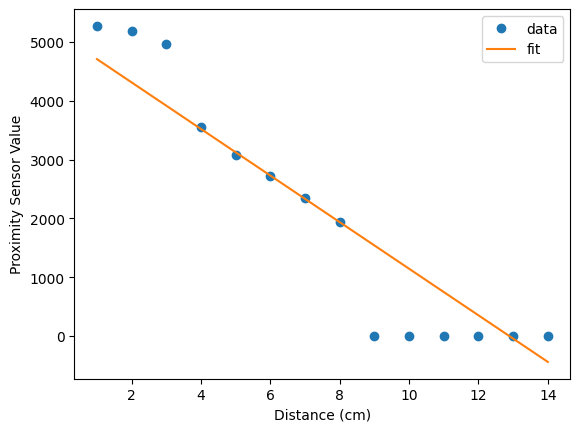

ENTER  (10 cm):  1145
EXIT   (12 cm):  353
DANGER (2.5 cm): 4115


In [12]:
d = np.array(distances); v = np.array(values)
ok = (d >= 4) & (v > 0)                     # TODO: also remove saturated points if you see any
a, b = np.polyfit(d[ok], v[ok], 1)
print(f"PROX_A = {a:.2f}, PROX_B = {b:.1f}")

plt.plot(distances, values, 'o', label='data')
plt.plot(distances, a * np.array(distances) + b, '-', label='fit')
plt.xlabel('Distance (cm)')
plt.ylabel('Proximity Sensor Value')
plt.legend()
plt.show()

print(f"ENTER  (10 cm):  {a * 10 + b:.0f}")
print(f"EXIT   (12 cm):  {a * 12 + b:.0f}")
print(f"DANGER (2.5 cm): {a * 2.5 + b:.0f}")

In [11]:
SPEED = 100
# Straight line
await set_speeds(SPEED, SPEED); await client.sleep(10); await set_speeds(0, 0)

In [13]:
# Turn on the spot
await set_speeds(-SPEED, SPEED); await client.sleep(5); await set_speeds(0, 0)

In [37]:
measured_distance = 33          # TODO: measure with a ruler (cm)
SPEED_TO_CMS = measured_distance / 10 / SPEED

measured_angle = math.radians(130)             # TODO: measure (rad)
WHEEL_BASE = 9.5

In [39]:
def update_pose(pose, left, right, dt):
    x, y, theta = pose

    v_left = left * SPEED_TO_CMS
    v_right = right * SPEED_TO_CMS
    v = (v_left + v_right) / 2
    w = (v_right - v_left) / WHEEL_BASE

    theta_mid = theta + w * dt / 2
    x += v * np.cos(theta_mid) * dt 
    y += v * np.sin(theta_mid) * dt
    theta = ln.wrap_angle(theta + w * dt)

    return(x, y, theta)

In [36]:
pose = (0, 0, 0)
left, right = -100, 100
t_prev = time.time()
await set_speeds(left, right)
for _ in range(50):                      # about 5 s
    await client.sleep(0.1)
    t_now = time.time()
    pose = update_pose(pose, left, right, t_now - t_prev)
    t_prev = t_now
await set_speeds(0, 0)
print(f"odometry angle: {math.degrees(pose[2]):.0f} deg (wrapped to ±180)")
print("WHEEL_BASE =", WHEEL_BASE, " SPEED_TO_CMS =", SPEED_TO_CMS)

odometry angle: 140 deg (wrapped to ±180)
WHEEL_BASE = 14.544313261013205  SPEED_TO_CMS = 0.033


In [40]:
nav = LocalNavigation()
pose = (0, 0, 0)
waypoint = (80, 0)

def check(name, result, expected):
    status = "OK  " if result == expected else "FAIL"
    print(f"{status} {name}: got {result}, expected {expected}")

# Side choice
check("obstacle on the right -> LEFT",
      nav.choose_side([0, 0, 1000, 2500, 3000, 0, 0], pose, waypoint, None), "LEFT")
check("obstacle on the left -> RIGHT",
      nav.choose_side([3000, 2500, 1000, 0, 0, 0, 0], pose, waypoint, None), "RIGHT")
check("head-on, waypoint on the left -> LEFT",
      nav.choose_side([0, 0, 3000, 0, 0, 0, 0], pose, (80, 20), None), "LEFT")
check("head-on, waypoint on the right -> RIGHT",
      nav.choose_side([0, 0, 3000, 0, 0, 0, 0], pose, (80, -20), None), "RIGHT")

# Detection
check("nothing in front", nav.obstacle_detected([0] * 7), False)
check("obstacle in front",
      nav.obstacle_detected([0, 0, ln.ENTER_THRESHOLD + 100, 0, 0, 0, 0]), True)
check("rear sensors ignored", nav.obstacle_detected([0, 0, 0, 0, 0, 4000, 4000]), False)

# Calibration and thresholds
value_5cm = ln.PROX_A * 5 + ln.PROX_B
check("prox_to_distance at 5 cm", round(ln.prox_to_distance(value_5cm), 1), 5.0)
check("DANGER > ENTER > EXIT",
      ln.DANGER_THRESHOLD > ln.ENTER_THRESHOLD > ln.EXIT_THRESHOLD, True)
check("ENTER > MEASURE", ln.ENTER_THRESHOLD > ln.MEASURE_THRESHOLD, True)

# Waypoint switching
test_path = [(0, 0), (60, 0), (60, 60)]
check("waypoint reached -> next", next_waypoint_index(test_path, 1, (59, 0, 0)), 2)
check("not reached, not avoiding -> keep", next_waypoint_index(test_path, 1, (40, 0, 0)), 1)
check("passed while avoiding -> next",
      next_waypoint_index(test_path, 1, (66, 10, 0), avoiding=True), 2)
check("goal never skipped", next_waypoint_index(test_path, 2, (60, 60, 0)), 2)

# P controller: on the circle with the tangent heading -> drives straight
R = ln.OBSTACLE_RADIUS + ln.ROBOT_HALF_WIDTH + ln.MARGIN
nav.side = "LEFT"                 # obstacle on the right, clockwise
nav.centre = (0, 0)
left, right = nav.circle_p_controller((0, -R, math.pi))
check("on the circle, tangent heading -> left == right", left == right, True)

OK   obstacle on the right -> LEFT: got LEFT, expected LEFT
OK   obstacle on the left -> RIGHT: got RIGHT, expected RIGHT
OK   head-on, waypoint on the left -> LEFT: got LEFT, expected LEFT
OK   head-on, waypoint on the right -> RIGHT: got RIGHT, expected RIGHT
OK   nothing in front: got False, expected False
OK   obstacle in front: got True, expected True
OK   rear sensors ignored: got False, expected False
OK   prox_to_distance at 5 cm: got 5.0, expected 5.0
OK   DANGER > ENTER > EXIT: got True, expected True
OK   ENTER > MEASURE: got True, expected True
OK   waypoint reached -> next: got 2, expected 2
OK   not reached, not avoiding -> keep: got 1, expected 1
OK   passed while avoiding -> next: got 2, expected 2
OK   goal never skipped: got 2, expected 2
OK   on the circle, tangent heading -> left == right: got True, expected True


In [23]:
true_centre = (15, 3)            # TODO: measured position of the obstacle (cm)
robot_pose = (0, 0, 0)           # robot at the origin, facing +x

estimates = []
for _ in range(20):
    prox = read_prox()
    if max(prox[:5]) > ln.MEASURE_THRESHOLD:     # only good readings
        estimates.append(ln.estimate_obstacle_centre(prox, robot_pose))
    await client.sleep(0.1)

if estimates:
    mean = np.mean(estimates, axis=0)
    error = math.dist(mean, true_centre)
    print(f"{len(estimates)} estimates, mean = ({mean[0]:.1f}, {mean[1]:.1f}) cm, "
          f"error = {error:.1f} cm")
else:
    print("No reading above MEASURE_THRESHOLD: obstacle too far?")

20 estimates, mean = (15.1, 5.5) cm, error = 2.5 cm


In [49]:
DT = 0.1
GOAL_RADIUS = 3.0

def go_to_waypoint(pose, waypoint):
    """Simple stand-in for the motion control module (GLOBAL state)."""
    a = angle_to(pose, waypoint)
    v = 150 * max(0.0, math.cos(a))
    w = 150 * a
    return v - w, v + w

async def run_test(path, max_time=60):
    """Drive along path with local navigation. Returns (log, reached)."""
    for name in ["ENTER_THRESHOLD", "EXIT_THRESHOLD", "DANGER_THRESHOLD",
                 "MIN_LOCAL_STEPS", "OBSTACLE_RADIUS", "MARGIN",
                 "TURN_SPEED", "ARC_SPEED"]:
        if getattr(ln, name) is Ellipsis:
            raise ValueError(f"{name} is not set in local_navigation.py")

    nav = LocalNavigation()
    pose = (path[0][0], path[0][1], 0.0)   # robot placed at the start, facing +x
    index = 1
    left = right = 0
    reached = False
    log = []
    t_start = t_prev = time.time()

    try:
        while time.time() - t_start < max_time:
            t_now = time.time()
            dt = t_now - t_prev
            t_prev = t_now

            pose = update_pose(pose, left, right, dt)   # motion since last step
            prox = read_prox()

            index = next_waypoint_index(path, index, pose,
                                        avoiding=(nav.state == "LOCAL"))
            if index == len(path) - 1 and math.dist(pose[:2], path[-1]) < GOAL_RADIUS:
                reached = True
                break

            state, left, right = nav.update(prox, pose, path[index])
            if state == "GLOBAL":
                left, right = go_to_waypoint(pose, path[index])
            left = int(np.clip(left, -500, 500))
            right = int(np.clip(right, -500, 500))
            await set_speeds(left, right)

            log.append(dict(t=t_now - t_start, dt=dt, pose=pose, prox=prox,
                            state=nav.state, phase=nav.phase, side=nav.side,
                            centre=nav.centre, index=index,
                            left=left, right=right))
            await client.sleep(max(0, DT - (time.time() - t_now)))
    finally:
        await set_speeds(0, 0)

    print("goal reached" if reached else "time out")
    return log, reached


SCENARIOS = {
    # true obstacle positions (x, y) in cm, measured, only used for the plots
    "centre":      dict(path=[(0, 0), (80, 0)],            obstacles=[(40, 0)]),
    "left":        dict(path=[(0, 0), (80, 0)],            obstacles=[(40, 4)]),
    "right":       dict(path=[(0, 0), (80, 0)],            obstacles=[(40, -4)]),
    "on_waypoint": dict(path=[(0, 0), (50, 0), (50, 50)],  obstacles=[(50, 0)]),
    "before_turn": dict(path=[(0, 0), (50, 0), (80, 40)],  obstacles=[(30, 0)]),
    "two":         dict(path=[(0, 0), (110, 0)],           obstacles=[(35, 0), (80, -2)]),
    "moving":      dict(path=[(0, 0), (80, 0)],            obstacles=[(40, 0)]),
}

In [ ]:
scenario = "left"              # TODO: change for each run
log, reached = await run_test(SCENARIOS[scenario]["path"])

goal reached


In [ ]:
def plot_run(log, path, obstacles, title=""):
    """Trajectory coloured by state + prox values over time."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Left: trajectory
    ax1.plot(*zip(*path), "k--o", lw=1, label="path")
    for ox, oy in obstacles:
        ax1.add_patch(plt.Circle((ox, oy), ln.OBSTACLE_RADIUS, color="grey"))
    for state, colour in (("GLOBAL", "tab:blue"), ("LOCAL", "tab:red")):
        pts = [e["pose"][:2] for e in log if e["state"] == state]
        if pts:
            ax1.plot(*zip(*pts), ".", ms=3, color=colour, label=state)
    centres = [e["centre"] for e in log if e["centre"] is not None]
    if centres:
        cx, cy = centres[-1]
        R = ln.OBSTACLE_RADIUS + ln.ROBOT_HALF_WIDTH + ln.MARGIN
        ax1.plot(cx, cy, "rx", ms=10, label="estimated centre")
        ax1.add_patch(plt.Circle((cx, cy), R, fill=False, ls=":", color="tab:red"))
    ax1.set_aspect("equal")
    ax1.set_xlabel("x [cm]"); ax1.set_ylabel("y [cm]")
    ax1.set_title(title)
    ax1.legend(fontsize=8)

    # Right: front prox over time with the thresholds
    t = [e["t"] for e in log]
    for i in range(5):
        ax2.plot(t, [e["prox"][i] for e in log], label=f"prox[{i}]")
    for value, name in ((ln.ENTER_THRESHOLD, "ENTER"), (ln.EXIT_THRESHOLD, "EXIT"),
                        (ln.DANGER_THRESHOLD, "DANGER")):
        ax2.axhline(value, ls="--", color="grey")
        ax2.text(0, value, name, fontsize=8, va="bottom")
    local = [e["state"] == "LOCAL" for e in log]
    ax2.fill_between(t, 0, 5000, where=local, color="tab:red", alpha=0.1,
                     label="LOCAL")
    ax2.set_xlabel("time [s]"); ax2.set_ylabel("prox value")
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

plot_run(log, SCENARIOS[scenario]["path"], SCENARIOS[scenario]["obstacles"],
         title=f"{scenario}: reached={reached}")

In [ ]:
if "results" not in globals():
    results = []                 

def add_result(scenario, log, reached, collision, notes=""):
    """Store one run. collision: what you saw (True/False)."""
    states = [e["state"] for e in log]
    entries = sum(1 for a, b in zip(["GLOBAL"] + states, states)
                  if a == "GLOBAL" and b == "LOCAL")
    results.append(dict(
        scenario=scenario,
        success=reached and not collision,
        reached=reached,
        collision=collision,
        total_time=round(log[-1]["t"], 1) if log else 0,
        local_time=round(sum(e["dt"] for e in log if e["state"] == "LOCAL"), 1),
        local_entries=entries,
        side=next((e["side"] for e in log if e["state"] == "LOCAL"), None),
        notes=notes,
    ))

In [ ]:
add_result(scenario, log, reached, collision=False, notes="")   # TODO: set collision

print(f"{'scenario':12s} {'success':8s} {'collision':10s} {'total':>6s} {'local':>6s} {'entries':>8s} side")
for r in results:
    print(f"{r['scenario']:12s} {str(r['success']):8s} {str(r['collision']):10s} "
          f"{r['total_time']:6.1f} {r['local_time']:6.1f} {r['local_entries']:8d} {r['side']}")

In [ ]:
await set_speeds(0, 0)
await node.unlock()